# 02 · From one neuron to EmotionNet

**Read first:** `01_theory/03_images_nn.md` (chapter 4), `01_theory/05_cnn.md`

1. a neuron, ReLU, softmax and cross-entropy — the numbers from the theory, by hand and in PyTorch
2. one step of gradient descent with `backward()`
3. convolution by hand = `torch.nn.functional.conv2d`, and what learned-looking kernels do to a face
4. output sizes with stride and padding
5. the residual block and **EmotionNet** — exactly **4,900,551** parameters, counted layer by layer
6. logits, not probabilities — and why `model.eval()` matters

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

_ = torch.manual_seed(0)

## 1. A neuron, softmax, cross-entropy

In [2]:
x = torch.tensor([0.5, -1.0, 2.0]); w = torch.tensor([0.8, 0.3, -0.4]); b = 0.1
s = (x * w).sum() + b
print(f"sum = {s:.2f}   ReLU -> {torch.relu(s):.2f}")

logits = torch.tensor([2.0, 0.5, -1.0])
print("softmax:", torch.softmax(logits, 0).numpy().round(3), "   (theory: 0.785 0.175 0.039)")
for p in (0.80, 0.10, 0.99):
    print(f"P(right answer) = {p:.2f}  ->  loss = -ln p = {-np.log(p):.2f}")

sum = -0.60   ReLU -> 0.00
softmax: [0.786 0.175 0.039]    (theory: 0.785 0.175 0.039)
P(right answer) = 0.80  ->  loss = -ln p = 0.22
P(right answer) = 0.10  ->  loss = -ln p = 2.30
P(right answer) = 0.99  ->  loss = -ln p = 0.01


`CrossEntropyLoss` takes **logits** and applies softmax itself:

In [3]:
target = torch.tensor([0])
print("CrossEntropyLoss(logits)          :", F.cross_entropy(logits[None], target).item())
print("-ln softmax(logits)[0]            :", -torch.log_softmax(logits, 0)[0].item())
print("CrossEntropyLoss(softmax(logits)) :", F.cross_entropy(torch.softmax(logits, 0)[None], target).item(), " <- softmax twice: WRONG")

CrossEntropyLoss(logits)          : 0.24131132662296295
-ln softmax(logits)[0]            : 0.24131132662296295
CrossEntropyLoss(softmax(logits)) : 0.7017174959182739  <- softmax twice: WRONG


## 2. One step of gradient descent — `backward()` computes the gradient for us

In [4]:
w = torch.tensor(0.80, requires_grad=True)
loss = (w * 3.0 - 1.15) ** 2          # some loss that depends on w
loss.backward()
print(f"w = {w.item():.3f}   loss = {loss.item():.4f}   dL/dw = {w.grad.item():.3f}")
with torch.no_grad():
    w -= 0.01 * w.grad
print(f"after one step with lr = 0.01:  w = {w.item():.4f}   new loss = {((w * 3.0 - 1.15) ** 2).item():.4f}")

w = 0.800   loss = 1.5625   dL/dw = 7.500
after one step with lr = 0.01:  w = 0.7250   new loss = 1.0506


## 3. Convolution — by hand, then in PyTorch

In [5]:
window = torch.tensor([[10., 10, 200], [10, 10, 200], [10, 10, 200]])
kernel = torch.tensor([[-1., 0, 1], [-1, 0, 1], [-1, 0, 1]])
print("by hand  :", (window * kernel).sum().item(), "  (theory: 570)")
print("conv2d   :", F.conv2d(window[None, None], kernel[None, None]).item())

by hand  : 570.0   (theory: 570)
conv2d   : 570.0


The network learns its own kernels — but classic hand-made ones show what kernels *can* see. Apply three of them
to a real face:

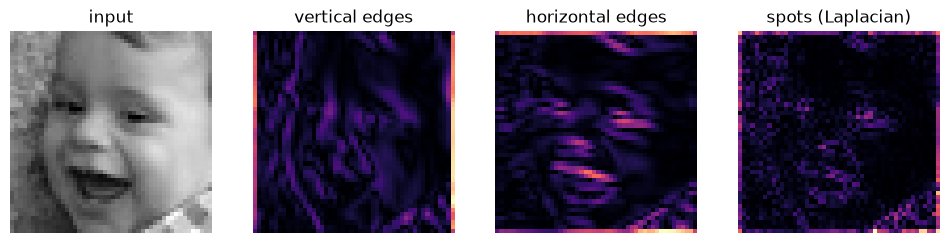

In [6]:
root = Path("../data/fer2013/train/happy")
face = torch.tensor(cv2.imread(str(sorted(root.iterdir())[3]), 0), dtype=torch.float32)[None, None] / 255
kernels = {"vertical edges": [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]],
           "horizontal edges": [[-1, -1, -1], [0, 0, 0], [1, 1, 1]],
           "spots (Laplacian)": [[0, -1, 0], [-1, 4, -1], [0, -1, 0]]}
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(face[0, 0], cmap="gray"); axes[0].set_title("input")
for a, (name, k) in zip(axes[1:], kernels.items()):
    a.imshow(F.conv2d(face, torch.tensor(k, dtype=torch.float32)[None, None], padding=1)[0, 0].abs(), cmap="magma")
    a.set_title(name)
for a in axes: a.axis("off")
plt.show()

## 4. Output sizes

$$ \text{out} = \Big\lfloor \frac{n + 2p - k}{s} \Big\rfloor + 1 $$

In [7]:
for n, s, p in ((48, 1, 1), (48, 2, 1), (24, 2, 1), (12, 2, 1), (12, 2, 0)):
    formula = (n + 2 * p - 3) // s + 1
    real = nn.Conv2d(1, 1, 3, stride=s, padding=p)(torch.zeros(1, 1, n, n)).shape[-1]
    print(f"{n}x{n}, 3x3, stride {s}, padding {p}:  formula {formula}   PyTorch {real}")

48x48, 3x3, stride 1, padding 1:  formula 48   PyTorch 48
48x48, 3x3, stride 2, padding 1:  formula 24   PyTorch 24
24x24, 3x3, stride 2, padding 1:  formula 12   PyTorch 12
12x12, 3x3, stride 2, padding 1:  formula 6   PyTorch 6
12x12, 3x3, stride 2, padding 0:  formula 5   PyTorch 5


## 5. The residual block and EmotionNet

`out = relu(F(x) + x)`. When the stride or the channels change, the shortcut is a 1×1 convolution that only
matches the shape.

In [8]:
class ResidualBlock(nn.Module):
    def __init__(self, c_in, c_out, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.shortcut = nn.Identity()
        if stride != 1 or c_in != c_out:
            self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm2d(c_out))

    def forward(self, x):
        identity = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + identity)                  # <- the jump

class EmotionNet(nn.Module):
    def __init__(self, n_classes=7, dropout=0.3):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 64, 3, 1, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU())
        self.block1 = ResidualBlock(64, 64, 1)
        self.block2 = ResidualBlock(64, 128, 2)
        self.block3 = ResidualBlock(128, 256, 2)
        self.block4 = ResidualBlock(256, 512, 2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(512, n_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.block4(self.block3(self.block2(self.block1(x))))
        return self.head(self.dropout(self.pool(x).flatten(1)))        # LOGITS

net = EmotionNet()
x = torch.zeros(2, 1, 48, 48)
shape = net.stem(x)
print(f"{'input':8s} {tuple(x.shape)}")
print(f"{'stem':8s} {tuple(shape.shape)}")
for name in ("block1", "block2", "block3", "block4"):
    shape = getattr(net, name)(shape)
    print(f"{name:8s} {tuple(shape.shape)}")
print(f"{'output':8s} {tuple(net(x).shape)}")

input    (2, 1, 48, 48)
stem     (2, 64, 48, 48)
block1   (2, 64, 48, 48)
block2   (2, 128, 24, 24)
block3   (2, 256, 12, 12)
block4   (2, 512, 6, 6)
output   (2, 7)


### Counting the parameters — layer by layer, like theory §5.6

In [9]:
for name in ("stem", "block1", "block2", "block3", "block4", "head"):
    n = sum(p.numel() for p in getattr(net, name).parameters())
    print(f"{name:7s} {n:>10,}")
total = sum(p.numel() for p in net.parameters())
print(f"{'total':7s} {total:>10,}   (theory: 4,900,551)")
print(f"block4 holds {sum(p.numel() for p in net.block4.parameters()) / total:.0%} of all parameters")

stem           704
block1      73,984
block2     230,144
block3     919,040
block4   3,673,088
head         3,591
total    4,900,551   (theory: 4,900,551)
block4 holds 75% of all parameters


## 6. Logits — and the `train()` / `eval()` switch

In [10]:
out = net(torch.randn(1, 1, 48, 48))
print("forward() output sums to", round(out.sum().item(), 3), "-> logits, not probabilities")
print("softmax of it sums to   ", round(torch.softmax(out, 1).sum().item(), 3))

img = torch.randn(1, 1, 48, 48)
net.train()
a, b = net(img), net(img)
print("train mode, same image twice -> same output?", torch.allclose(a, b), "  (Dropout is random)")
net.eval()
with torch.no_grad():
    a, b = net(img), net(img)
print("eval mode,  same image twice -> same output?", torch.allclose(a, b))

forward() output sums to 0.159 -> logits, not probabilities
softmax of it sums to    1.0
train mode, same image twice -> same output? False   (Dropout is random)


eval mode,  same image twice -> same output? True


Forgetting `model.eval()` before real-time inference = random answers. You will be asked about this.

## ✍️ Try it yourself

1. Apply the Laplacian `[[0,-1,0],[-1,4,-1],[0,-1,0]]` to `[[10,10,10],[10,50,10],[10,10,10]]` by hand. Check with
   `F.conv2d`.
2. Count the parameters of `Conv2d(32, 64, 3, bias=True)` with the formula, then with PyTorch.
3. Remove the 1×1 shortcut in block2 (`self.shortcut = nn.Identity()` always). What error do you get, and why?

Then solve exercises 4–7 in `03_exercises/`.